In [1]:
import time
start_time=time.time()

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [3]:
# Add path to py_modules 
sys.path.append(str(Path().resolve().parents[0] / 'py_modules')) # 1 level up = project root

# Add path to pipeline_config.py
sys.path.append(str(Path().resolve().parents[0]))  # 1 level up = project root

# Import from pipeline_config and py_modules
from pipeline_config import OBSERVATIONS_DIR, MAPS_DIR, FIGS_DIR

In [4]:
name_export='MUSE-Dor-H'
data_file = name_export + '.fits'

In [5]:
fits_file = OBSERVATIONS_DIR / data_file

In [6]:
with fits.open(fits_file) as hdul:
    n = None
    sb_raw = hdul[1].data[:n, :n].astype(np.float64)
    vv_raw = hdul[2].data[:n, :n].astype(np.float64)
    ss_raw = hdul[3].data[:n, :n].astype(np.float64)
    hdul.info()

Filename: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\MUSE_30dor\observations\MUSE-Dor-H.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1158   ()      
  1  DATA          1 ImageHDU        52   (650, 650)   float64   
  2  DATA          1 ImageHDU        52   (650, 650)   float64   
  3  DATA          1 ImageHDU        52   (650, 650)   float64   


In [7]:
m = ~np.isfinite(sb_raw*vv_raw*ss_raw) | (sb_raw < 0.0)

sb = sb_raw
vv = vv_raw
ss = ss_raw

sb[m] = 0.0
#vv[m] = np.nanmean(vv)
sb /= sb.max()

good = (~m) & (sb > 0.001)

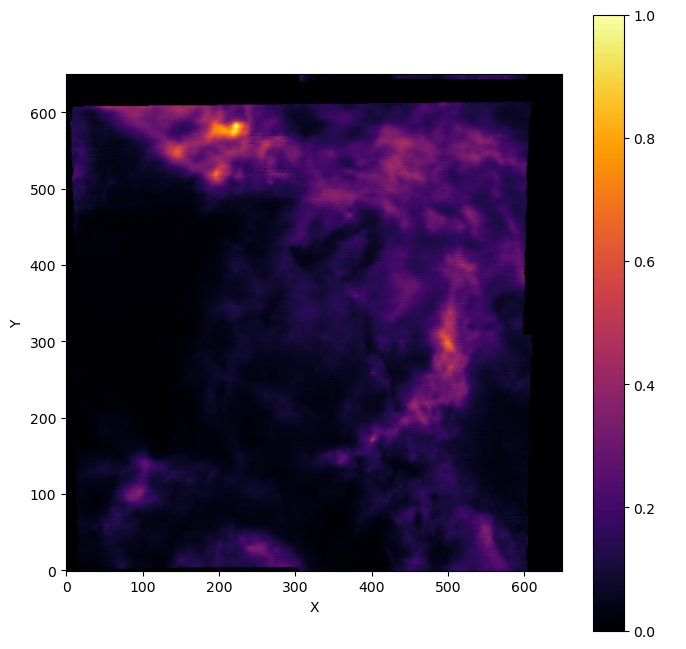

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))

plt.figure(1)
plt.imshow(sb, cmap='inferno')

cbar = plt.colorbar()
#plt.clim(0.001,1)
cbar.set_label(' ', rotation=270, labelpad=15)  

ax.set_xlabel('X')
ax.set_ylabel('Y')

plt.gca().invert_yaxis()

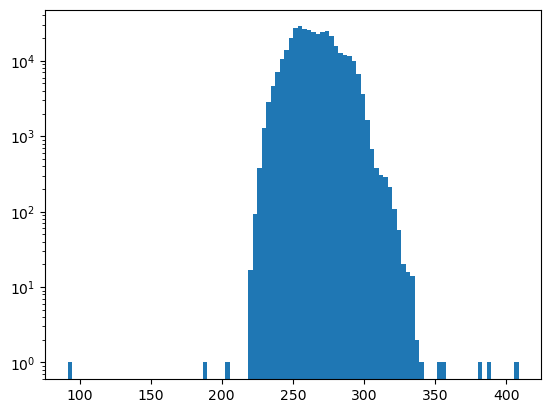

In [9]:
fig, ax = plt.subplots()
plt.hist(vv[np.isfinite(vv)& (np.abs(vv) < 600)] , bins=100)
ax.set_yscale("log")

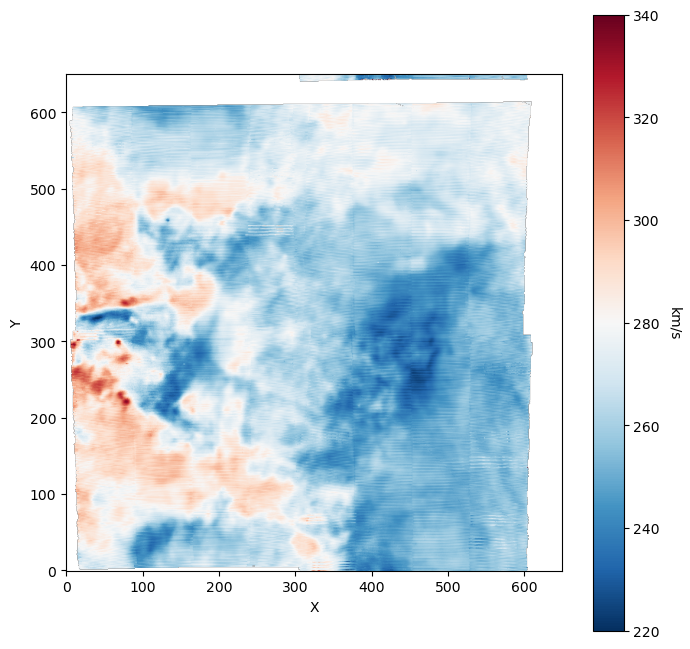

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))

plt.figure(1)
plt.imshow(vv, cmap='RdBu_r')

cbar = plt.colorbar()
plt.clim(220,340)
cbar.set_label('km/s', rotation=270, labelpad=15)  

ax.set_xlabel('X')
ax.set_ylabel('Y')

plt.gca().invert_yaxis()

In [11]:
vv = np.where(~m, vv, np.nan)     
sb = np.where(~m, sb, np.nan) 

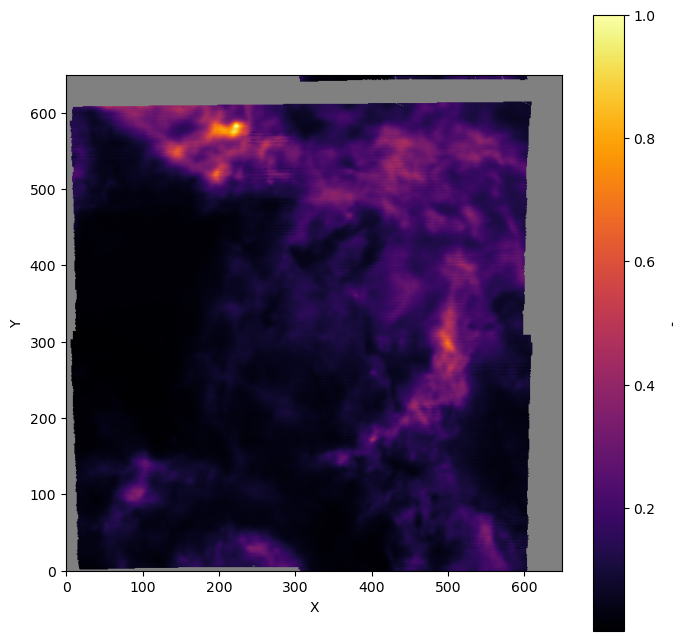

In [12]:
fig, ax = plt.subplots(figsize=(8, 8))

# Get colormap and define color for NaN/masked values
cmap = plt.cm.inferno.copy()
cmap.set_bad(color='gray')

# Plot
im = ax.imshow(
    sb,
    cmap=cmap,
#    vmin=220,
#    vmax=340
)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('-', rotation=270, labelpad=15)

# Labels
ax.set_xlabel('X')
ax.set_ylabel('Y')

ax.invert_yaxis()

plt.show()

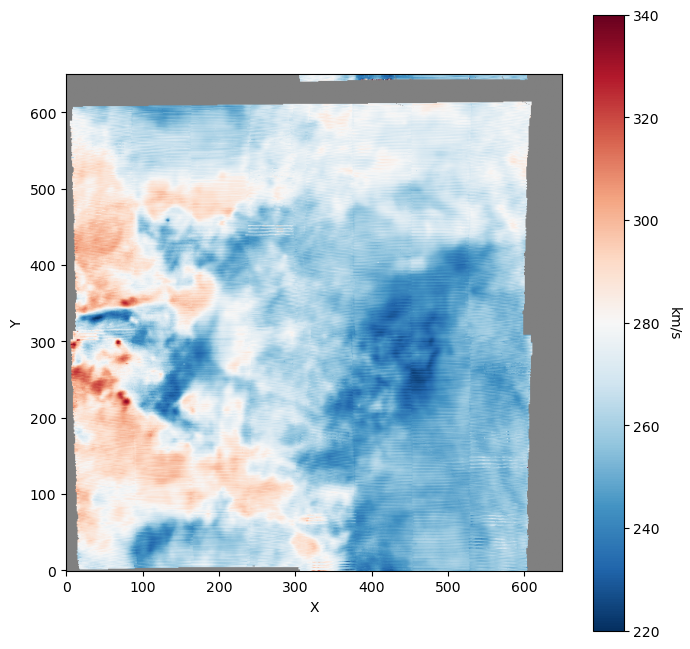

In [13]:
fig, ax = plt.subplots(figsize=(8, 8))

# Get colormap and define color for NaN/masked values
cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color='gray')

# Plot
im = ax.imshow(
    vv,
    cmap=cmap,
    vmin=220,
    vmax=340
)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('km/s', rotation=270, labelpad=15)

# Labels
ax.set_xlabel('X')
ax.set_ylabel('Y')

ax.invert_yaxis()

plt.show()

In [14]:
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
import astropy.units as u
c0 = SkyCoord.from_name("Tarantula")
c0

<SkyCoord (ICRS): (ra, dec) in deg
    (84.675, -69.1)>

In [15]:
ra_deg = c0.ra.deg
dec_deg = c0.dec.deg

In [16]:
# MUSE image array

# Array shape
ny, nx = sb.shape

# MUSE pixel scale
pixscale_arcsec = 0.2
pixscale_deg = pixscale_arcsec / 3600.0

# Approximate image center in sky coordinates
#ra0 = 84.675
#dec0 = -69.1

# Create WCS object
wcs_muse = WCS(naxis=2)

wcs_muse.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs_muse.wcs.crval = [ra_deg, dec_deg]

# FITS/WCS uses 1-based reference pixels
wcs_muse.wcs.crpix = [nx  / 2, ny / 2]

# RA axis usually has negative pixel scale
wcs_muse.wcs.cdelt = [-pixscale_deg, pixscale_deg]

wcs_muse

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN' 
CRVAL : 84.675 -69.1 
CRPIX : 325.0 325.0 
PC1_1 PC1_2  : 1.0 0.0 
PC2_1 PC2_2  : 0.0 1.0 
CDELT : -5.555555555555556e-05 5.555555555555556e-05 
NAXIS : 0  0

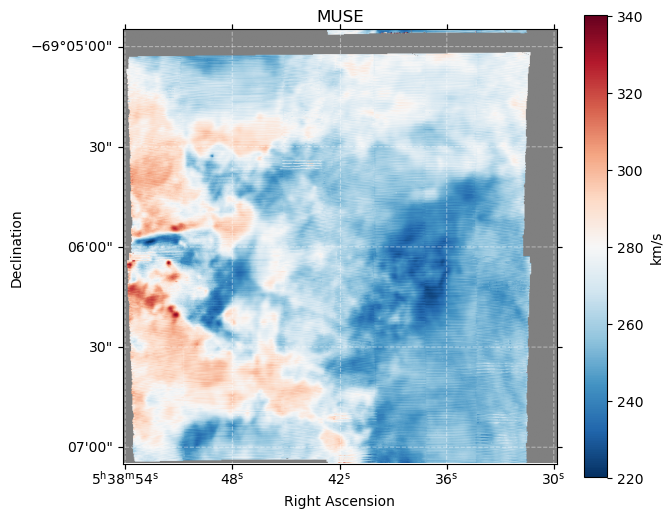

In [17]:
fig = plt.figure(figsize=(7, 6))

ax = fig.add_subplot(1, 1, 1, projection=wcs_muse)

im = ax.imshow(
    vv,
    origin="lower",
    cmap="RdBu_r",
    vmin=220,
    vmax=340,
)


plt.colorbar(im, ax=ax, label="km/s")

ax.set_xlabel("Right Ascension")
ax.set_ylabel("Declination")
ax.set_title("MUSE")

ax.grid(color="white", alpha=0.4, linestyle="--")
im.cmap.set_bad(color='gray')

plt.show()

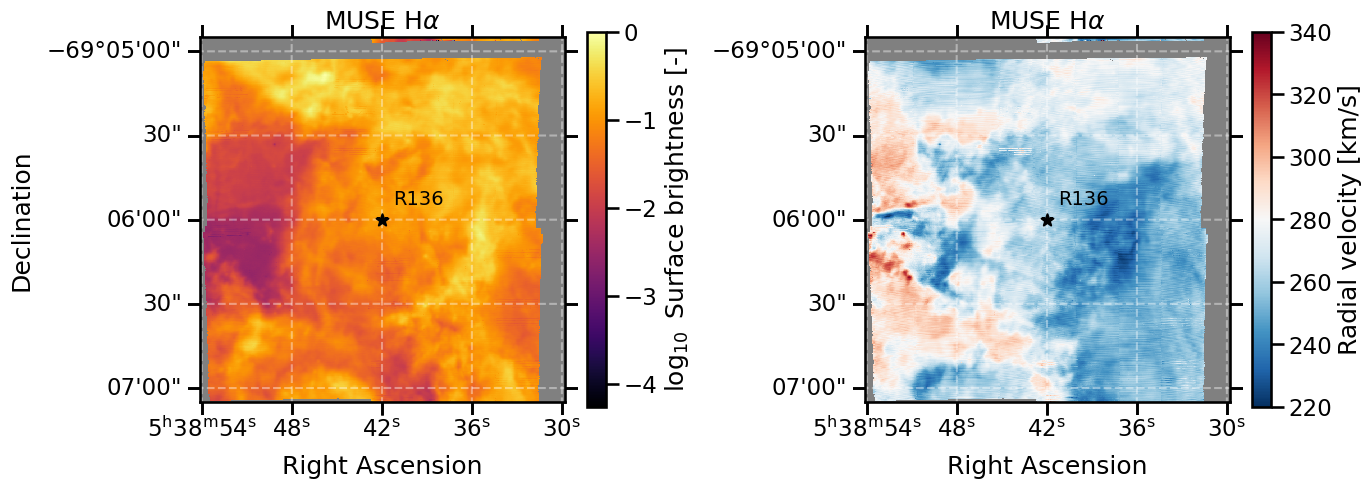

In [18]:
sns.set_context("talk")


fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 6),
    subplot_kw={"projection": wcs_muse}
)

# -------------------------------------------------------
# Left panel: Surface brightness
# -------------------------------------------------------
im1 = ax1.imshow(
    np.log10(sb),
    origin="lower",
    cmap="inferno",
    interpolation="nearest"
)

cbar1 = fig.colorbar(
    im1,
    ax=ax1,
    label=r"$\log_{10}$ Surface brightness [-]",
    shrink=0.8
)

ax1.set_xlabel("Right Ascension")
ax1.set_ylabel("Declination")
ax1.set_title(r"MUSE H$\alpha$")

ax1.grid(
    color="white",
    alpha=0.4,
    linestyle="--"
)

# R136 position
ax1.scatter(
    c0.ra.deg,
    c0.dec.deg,
    transform=ax1.get_transform("world"),
    color="black",
    s=80,
    marker="*",
    zorder=5
)

ax1.annotate(
    "R136",
    xy=(c0.ra.deg, c0.dec.deg),
    xycoords=ax1.get_transform("world"),
    xytext=(8, 8),
    textcoords="offset points",
    color="black",
    fontsize=14,
    ha="left",
    va="bottom"
)

im1.cmap.set_bad(color="gray")


# -------------------------------------------------------
# Right panel: Radial velocity
# -------------------------------------------------------
im2 = ax2.imshow(
    vv,
    origin="lower",
    cmap="RdBu_r",
    vmin=220,
    vmax=340,
    interpolation="nearest"
)

cbar2 = fig.colorbar(
    im2,
    ax=ax2,
    label="Radial velocity [km/s]",
    shrink=0.8
)

ax2.set_xlabel("Right Ascension")
ax2.set_ylabel("")
ax2.set_title(r"MUSE H$\alpha$")

ax2.grid(
    color="white",
    alpha=0.4,
    linestyle="--"
)

# R136 position
ax2.scatter(
    c0.ra.deg,
    c0.dec.deg,
    transform=ax2.get_transform("world"),
    color="black",
 #   edgecolor="white",  
    s=80,
    marker="*",
    zorder=5
)

ax2.annotate(
    "R136",
    xy=(c0.ra.deg, c0.dec.deg),
    xycoords=ax2.get_transform("world"),
    xytext=(8, 8),
    textcoords="offset points",
    color="black",
 #   edgecolor="white",  
    fontsize=14,
    ha="left",
    va="bottom"
)

im2.cmap.set_bad(color="gray")


# -------------------------------------------------------
# Layout
# -------------------------------------------------------
plt.tight_layout()

plt.savefig(FIGS_DIR / f"{name_export}.pdf", 
            dpi=300, 
bbox_inches='tight')

plt.show()

In [19]:
name_export

'MUSE-Dor-H'

In [20]:
print("--- %s seconds ---" % (time.time()-start_time))

--- 10.691337823867798 seconds ---
